# 01 · Exploratory data analysis: IBM AMLworld HI-Small

This notebook is for exploration only. Every reusable step lives in `src/aml_sentinel`.
The data is **synthetic**, so these findings describe the simulator, not real banks.

To regenerate the input, run `make data`, which writes `data/processed/HI-Small.parquet`.

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from aml_sentinel.config import load_settings
from aml_sentinel.data.schema import Col
from aml_sentinel.graph import build_account_graph

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
settings = load_settings(data_dir=ROOT / "data")
df = pd.read_parquet(settings.processed_dir / "HI-Small.parquet")
print(
    f"{len(df):,} rows, {df[Col.IS_LAUNDERING].sum():,} laundering "
    f"({df[Col.IS_LAUNDERING].mean():.3%})"
)

5,078,345 rows, 5,177 laundering (0.102%)


## 1. Class imbalance per split
The `tail` split is excluded from evaluation (ADR-003).

In [2]:
df.groupby("split", observed=True)[Col.IS_LAUNDERING].agg(rows="size", positives="sum", rate="mean")

,rows,positives,rate
split,,,
train,3248921,2530,0.000779
val,965524,1036,0.001073
test,862792,956,0.001108
tail,1108,655,0.591155


## 2. Daily volume: the collapsing tail

,rows,positives,rate
timestamp,,,
2022-09-01,1114921,322,0.000289
2022-09-02,754449,408,0.000541
2022-09-03,207382,391,0.001885
2022-09-04,207430,407,0.001962
2022-09-05,482650,471,0.000976
2022-09-06,482089,531,0.001101
2022-09-07,482751,497,0.001030
2022-09-08,482773,539,0.001116
2022-09-09,654467,514,0.000785


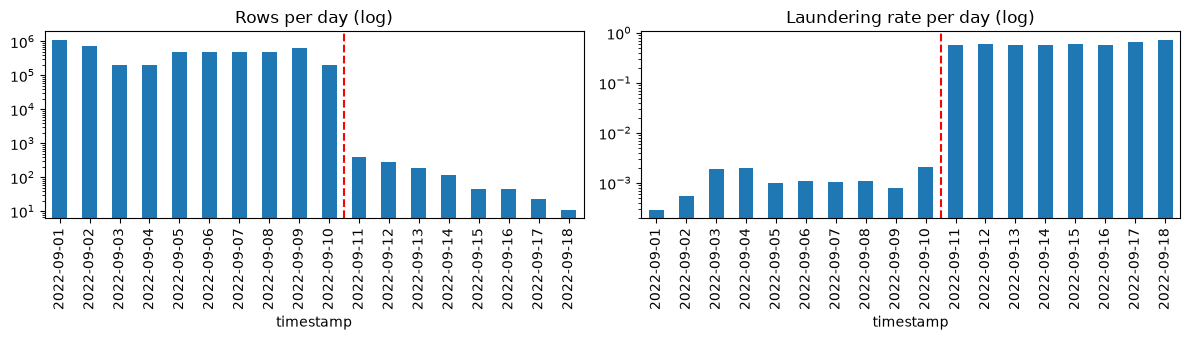

In [3]:
daily = df.groupby(df[Col.TIMESTAMP].dt.date)[Col.IS_LAUNDERING].agg(rows="size", positives="sum")
daily["rate"] = daily["positives"] / daily["rows"]
fig, ax = plt.subplots(1, 2, figsize=(12, 3.5))
daily["rows"].plot.bar(ax=ax[0], logy=True, title="Rows per day (log)")
daily["rate"].plot.bar(ax=ax[1], logy=True, title="Laundering rate per day (log)")
for a in ax:
    a.axvline(9.5, color="red", ls="--")
plt.tight_layout()
daily

## 3. Amounts (USD) by label

,count,mean,std,min,50%,90%,99%,max
is_laundering,,,,,,,,
0,5073168.0,3.460270e+05,2.323337e+07,0.000095,891.038251,35448.747445,3.099715e+06,2.655861e+10
1,5177.0,5.169485e+06,2.313315e+08,0.386689,5878.806939,18466.355746,1.579320e+07,1.629705e+10


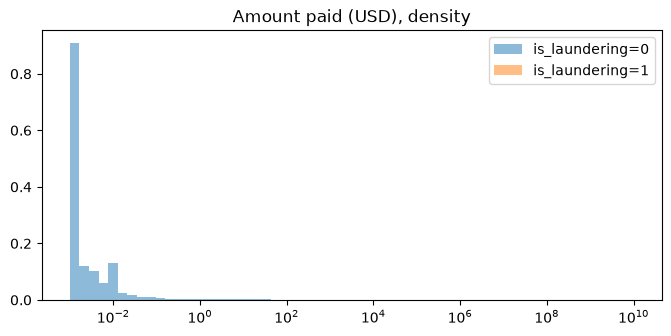

In [4]:
bins = np.logspace(-3, 10, 60)
fig, ax = plt.subplots(figsize=(8, 3.5))
for label, grp in df.groupby(Col.IS_LAUNDERING):
    ax.hist(
        grp[Col.AMOUNT_PAID_USD].clip(lower=1e-3),
        bins=bins,
        density=True,
        alpha=0.5,
        label=f"is_laundering={label}",
    )
ax.set_xscale("log")
ax.legend()
ax.set_title("Amount paid (USD), density")
df.groupby(Col.IS_LAUNDERING)[Col.AMOUNT_PAID_USD].describe(percentiles=[0.5, 0.9, 0.99])

## 4. Payment format and currency

In [5]:
fmt = df.groupby(Col.PAYMENT_FORMAT, observed=True)[Col.IS_LAUNDERING].agg(
    rows="size", positives="sum", rate="mean"
)
fmt.sort_values("rate", ascending=False)

,rows,positives,rate
payment_format,,,
ACH,600797,4483,0.007462
Bitcoin,146091,56,0.000383
Cash,490891,108,0.000220
Cheque,1864331,324,0.000174
Credit Card,1323324,206,0.000156
Reinvestment,481056,0,0.000000
Wire,171855,0,0.000000


In [6]:
cross = df[Col.PAYMENT_CURRENCY].astype(str) != df[Col.RECEIVING_CURRENCY].astype(str)
pd.DataFrame(
    {
        "cross_currency_rows": [cross.sum()],
        "rate_cross": [df.loc[cross, Col.IS_LAUNDERING].mean()],
        "rate_same": [df.loc[~cross, Col.IS_LAUNDERING].mean()],
    }
)

,cross_currency_rows,rate_cross,rate_same
0,72170,0.0,0.001034


## 5. Typology coverage
`NaN` means the transaction is in no documented attempt. It does not mean benign.

In [7]:
pos = df[df[Col.IS_LAUNDERING] == 1]
print(f"positives with typology: {pos['typology'].notna().mean():.1%}")
pos["typology"].value_counts(dropna=False)

positives with typology: 62.0%


typology
NaN               1968
GATHER-SCATTER     716
SCATTER-GATHER     626
STACK              466
FAN-OUT            342
FAN-IN             318
CYCLE              287
BIPARTITE          263
RANDOM             191
Name: count, dtype: int64

## 6. Self-transfers and account identity

In [8]:
self_loop = df[Col.FROM_ID].astype(str) == df[Col.TO_ID].astype(str)
print(
    f"self-transfers: {self_loop.mean():.1%} of rows; laundering rate {df.loc[self_loop, Col.IS_LAUNDERING].mean():.4%}"
)
print(df.loc[self_loop, Col.PAYMENT_FORMAT].value_counts().head(3))
acct = pd.concat(
    [
        df[[Col.FROM_BANK, Col.FROM_ACCOUNT]].set_axis(["bank", "account"], axis=1),
        df[[Col.TO_BANK, Col.TO_ACCOUNT]].set_axis(["bank", "account"], axis=1),
    ]
).drop_duplicates()
print(
    f"accounts: {len(acct):,}; account strings at >1 bank: {(acct.groupby('account', observed=True).size() > 1).sum():,}"
)

self-transfers: 11.6% of rows; laundering rate 0.0019%
payment_format
Reinvestment    481056
ACH              71347
Bitcoin          26317
Name: count, dtype: int64


accounts: 515,088; account strings at >1 bank: 8


## 7. Training-period account graph

nodes 408,244  edges 573,336
in-degree  p50=1 p99=6 max=545
out-degree p50=1 p99=8 max=14230


Text(0.5, 1.0, 'Degree distribution (train graph)')

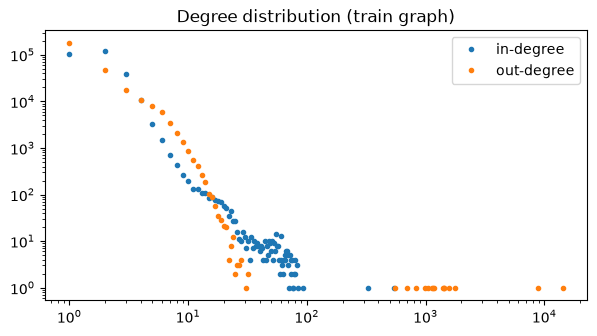

In [9]:
train = df[df["split"] == "train"]
g = build_account_graph(train)
deg_in = np.array([d for _, d in g.in_degree()])
deg_out = np.array([d for _, d in g.out_degree()])
print(f"nodes {g.number_of_nodes():,}  edges {g.number_of_edges():,}")
print(
    f"in-degree  p50={np.median(deg_in):.0f} p99={np.percentile(deg_in, 99):.0f} max={deg_in.max()}"
)
print(
    f"out-degree p50={np.median(deg_out):.0f} p99={np.percentile(deg_out, 99):.0f} max={deg_out.max()}"
)
fig, ax = plt.subplots(figsize=(7, 3.5))
for name, d in (("in", deg_in), ("out", deg_out)):
    vals, counts = np.unique(d, return_counts=True)
    ax.loglog(vals, counts, ".", label=f"{name}-degree")
ax.legend()
ax.set_title("Degree distribution (train graph)")

In [10]:
# Do laundering accounts look different structurally? (EDA only - no labels on the graph.)
bad = set(train.loc[train[Col.IS_LAUNDERING] == 1, Col.FROM_ID].astype(str))
stats = pd.DataFrame({"node": list(g.nodes), "in": deg_in, "out": deg_out})
stats["sends_laundering"] = stats["node"].isin(bad)
stats.groupby("sends_laundering")[["in", "out"]].describe(percentiles=[0.5, 0.9]).T

sends_laundering          False         True 
in  count         406499.000000   1745.000000
    mean               1.399716      2.494556
    std                2.052718     15.815163
    min                0.000000      0.000000
    50%                1.000000      1.000000
    90%                3.000000      3.000000
    max               93.000000    545.000000
out count         406499.000000   1745.000000
    mean               1.306729     24.155874
    std                1.746072    414.028272
    min                0.000000      1.000000
    50%                1.000000      2.000000
    90%                3.000000      4.000000
    max               32.000000  14230.000000

## Findings (HI-Small, measured on the executed notebook above)

1. **Imbalance.** 0.102% positives overall. Train has 0.078%, val 0.107% and test
   0.111%, so prevalence drifts upward over time. Calibration fitted on val
   matters.
2. **The tail artifact is confirmed.** From 09-11 on there are only 1,108 rows,
   and 59% of them are positive. They are excluded from evaluation (ADR-003).
3. **Payment format is a simulator shortcut.** ACH carries 4,483 of the 5,177
   positives (87%, a 0.75% rate). Wire and Reinvestment carry none. A model will
   lean on this heavily. Phase 3/8 must include an ablation *without*
   payment_format, and results must state the dependence.
4. **Cross-currency transfers are never laundering** (0 of 72,170). This is
   another simulator artifact, so treat it with the same caution as point 3.
5. **Amounts.** Laundering transactions are larger: the median is about
   5.9k USD versus 0.9k benign. Both distributions are very heavy-tailed, up to
   about 1e10 USD, so use log or rank features.
6. **Typology coverage.** Only 62% of positives belong to a documented attempt.
   The largest typologies are GATHER-SCATTER (716 rows) and SCATTER-GATHER (626).
7. **Account identity.** 8 account strings occur at more than one bank. This
   confirms ADR-002 (bank-qualified node IDs).
8. **Self-transfers.** These are 11.6% of rows, almost all Reinvestment, with a
   0.0019% laundering rate. They are excluded from graph edges.
9. **Train graph.** 408k nodes and 573k aggregated edges. The median degree is 1.
   Accounts that send laundering have a higher median out-degree (2 vs 1) and
   contain extreme hubs (max out-degree 14,230), which supports degree-based
   features.
